# calc_03b. ERA5: rank histograms (calculations)

Part 1 of the ERA5 evaluation, from notebook calc_03a: **is each model consistent with ERA5?** Could ERA5 be one more member of a model's historical ensemble? Here by the rank histograms of Suarez-Gutierrez et al. (2021): at one point, then the paper's grid-point evaluation on the maps (section 8) and the rank histograms of regional means (section 9). After the point tests, every test goes into one table: calc_03a's statistics, with ERA5 placed among the members here, and this notebook's rank tests.

Run calc_03a first: the table opens the statistics it saved (every member's value and ERA5's). The results are saved in `RESULTS_DIR` (`results/tas/sample` or `results/tas/full` under `SCRATCH_DIR`), beside calc_03a's; notebook plot_01 opens them and draws the figures. Part 2, the observed change, is notebook calc_03c.

## Setup

In [1]:
import sys
sys.path[:0] = ['..']   # this repository: the extant package and plotting_modules

import logging
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from extant import datatree, era5_evaluation as ev, observed_change as oc, preprocessing as pp
from extant.config import MAIN_EXPERIMENTS, SATELLITE_YEAR_RANGE, VARIABLES
from extant.datatree import skip_empty, tree_to_dataset
from extant.logger import setup_logging
from extant.plots import charts, forced_response as fr, methods
from plotting_modules.constants import FORCING_COLORS, SEASONS

logger = setup_logging('extant', logging.INFO)
xr.set_options(display_expand_attrs=False, display_expand_data=False)

#(t): Harmless warnings, silenced the same way in every notebook. zarr's, that parts of the stores (the text
#(t): coordinates, the consolidated metadata) aren't in the Zarr 3 standard yet:
warnings.filterwarnings('ignore', message='.*Zarr (format 3|V3) specification')
#(t): numpy's, about slices with nothing but NaN (land, a model without a member) or nothing at all, too few members for
#(t): a standard deviation, and dividing by zero or by NaN (the log of a probability of 0, say):
warnings.filterwarnings('ignore', message='All-NaN slice encountered', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Mean of empty slice', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Degrees of freedom <= 0 for slice', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='(divide by zero|invalid value) encountered', category=RuntimeWarning)
#(t): dask's, about large task graphs, which are large on purpose:
warnings.filterwarnings('ignore', message='.*Sending large graph of size', category=UserWarning)
#(t): Every figure's text at the notebook's sizes and colours (fr.NOTEBOOK), as in every notebook
plt.rcParams.update(fr.NOTEBOOK.rc)

In [2]:
%matplotlib inline

## Settings

The experiments (`MAIN_EXPERIMENTS`) and the years ERA5 and LESFMIP share (`SATELLITE_YEAR_RANGE`) are in `extant/config.py`, and the order of the seasons (`SEASONS`) in `plotting_modules/constants.py`, the same for every notebook. Only this notebook's own choices are here.

In [3]:
#(t): The variable: its name and its units once notebook calc_01 has converted it (VARIABLE.name, VARIABLE.units)
VARIABLE = VARIABLES['tas']

In [4]:
#(t): The grid point of the tests at one point (the 2.5° cell nearest config.POINT, on the Antarctic plateau)
SAMPLE_LAT_LON = dict(lat=-82.5, lon=120.0)

#(t): The model of the one-model quick looks
EXAMPLE_MODEL = 'CanESM5'

In [5]:
#(t): Where notebook calc_01's seasonal means are, and where this notebook's results go: JASMIN's scratch
SCRATCH_DIR = Path('/work/scratch-pw4/aborow/ExtAnt')
SCRATCH_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt')

## Open the Data

Run **one** of the next two sections. Both leave `lesfmip_season_tree` (seasonal means, /<model>/<experiment>, on member × year × season × lat × lon), `era5_seasonal_da` (ERA5 on year × season × lat × lon, on the same grid), all in °C, and `RESULTS_DIR`, where the results are saved.

### Sample data

The 3×3 block of grid cells around the point in `tests/data` (two models), put through notebook calc_01's pre-processing.

In [6]:
#(t): The sample's files, in this repository: <model>_<experiment>_sample.nc, monthly tas in K on (member, time, lat, lon)
SAMPLE_DIR = Path('../tests/data')
sample_files = sorted(SAMPLE_DIR.glob('*_*_sample.nc'))
sample_files

[PosixPath('../tests/data/CanESM5_hist-GHG_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-aer_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-lu_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-nat_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-sol_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-totalO3_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-volc_sample.nc'),
 PosixPath('../tests/data/CanESM5_historical_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-GHG_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-aer_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-lu_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-nat_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-sol_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-totalO3_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-volc_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_historical_sample.nc')]

In [7]:
#(t): The model and experiment of each file, from its name
sample_names = [path.stem.removesuffix('_sample').rsplit('_', 1) for path in sample_files]

In [8]:
#(t): Each file of the experiments analysed opened, as a DataTree /<model>/<experiment>
lesfmip_monthly_tree = xr.DataTree.from_dict({f'{model}/{experiment}': xr.open_dataset(path).load()
                                              for path, (model, experiment) in zip(sample_files, sample_names)
                                              if experiment in MAIN_EXPERIMENTS})

In [9]:
#(t): Seasonal means in °C, through notebook calc_01's pre-processing (pp.seasonal_tree: to °C, cut at 2014-12, complete
#(t): seasons in whole years)
lesfmip_season_tree = pp.seasonal_tree(lesfmip_monthly_tree, VARIABLE.name).compute()

In [10]:
#(t): ERA5's sample file: monthly tas in K from 1979, on (time, lat, lon)
era5_sample_path = SAMPLE_DIR / 'era5_sample.nc'
era5_monthly_da = xr.open_dataarray(era5_sample_path).load()
era5_sample_path

PosixPath('../tests/data/era5_sample.nc')

In [11]:
#(t): Its seasonal means in °C, on the models' grid (pp.seasonal_era5, as in notebook calc_01)
era5_seasonal_da = pp.seasonal_era5(era5_monthly_da, VARIABLE.name, like=lesfmip_season_tree)

In [12]:
#(t): Where the sample's results are saved
RESULTS_DIR = SCRATCH_DIR / 'results' / VARIABLE.name / 'sample'
RESULTS_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/sample')

### Full data

The seasonal means notebook calc_01 saved (section 3) in `SCRATCH_DIR`. Opening is lazy.

In [13]:
#(t): The two stores notebook calc_01 saved
seasonal_path = SCRATCH_DIR / 'seasonal' / f'lesfmip_{VARIABLE.name}.zarr'
era5_path = SCRATCH_DIR / 'seasonal' / f'era5_{VARIABLE.name}.zarr'
seasonal_path, era5_path

(PosixPath('/work/scratch-pw4/aborow/ExtAnt/seasonal/lesfmip_tas.zarr'),
 PosixPath('/work/scratch-pw4/aborow/ExtAnt/seasonal/era5_tas.zarr'))

In [14]:
#(t): Every model and experiment notebook calc_01 saved
lesfmip_saved_tree = xr.open_datatree(seasonal_path, engine='zarr', chunks={})

In [15]:
#(t): Only the experiments analysed (filter keeps the model nodes above them)
lesfmip_season_tree = lesfmip_saved_tree.filter(lambda node: node.name in MAIN_EXPERIMENTS)

In [16]:
#(t): ERA5's seasonal means
era5_seasonal_da = xr.open_zarr(era5_path)[VARIABLE.name].load()

In [17]:
#(t): Where the full data's results are saved
RESULTS_DIR = SCRATCH_DIR / 'results' / VARIABLE.name / 'full'
RESULTS_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full')

### What was opened

Whichever section ran. An empty square is a model and experiment that was never opened.

In [18]:
#(t): Members per model (rows) and experiment (columns)
member_counts_df = pd.Series({(node.parent.name, node.name): node.sizes['member']
                              for node in lesfmip_season_tree.leaves}).unstack()
member_counts_df = member_counts_df.reindex(columns=MAIN_EXPERIMENTS)

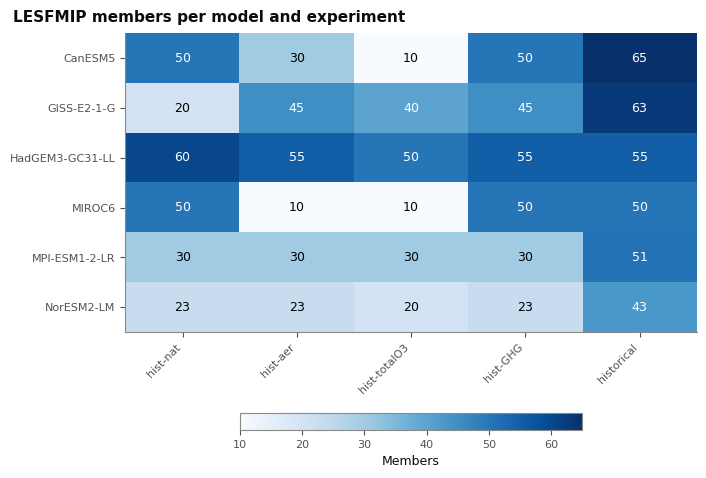

In [19]:
#(t): The members: each model (rows) and experiment (columns), grey where there are none
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=1, n_legends=0, n_colorbars=1,
                                                  panel_width=0.9 * member_counts_df.shape[1] + 0.5,
                                                  panel_height=0.4 * member_counts_df.shape[0] + 0.3, left_margin=1.8),
                 layout='constrained')
axes = fig.add_gridspec(1, 1).subplots(squeeze=False)
counts_image = methods.plot_member_counts(member_counts_df, ax=axes[0, 0])
fig.colorbar(counts_image, ax=axes, location='bottom', shrink=0.6, label='Members')
fig.suptitle('LESFMIP members per model and experiment', x=0.01, ha='left');

## Data at the Point

Each model's historical members and ERA5 over `SATELLITE_YEAR_RANGE`, made as notebook calc_03a makes them (calc_03a saves them for plot_01). The models stay in a DataTree, each with its own members; ERA5 is one DataArray.

In [51]:
#(t): LESFMIP over the years shared with ERA5
lesfmip_obs_tree = lesfmip_season_tree.sel(year=SATELLITE_YEAR_RANGE)

In [52]:
#(t): Each model's historical members at the point, on (member, year, season)
historical_point_tree = lesfmip_obs_tree.match('*/historical').sel(SAMPLE_LAT_LON).load()
historical_point_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   └── Group: /CanESM5/historical
│           Dimensions:  (member: 65, year: 35, season: 4)
│           Coordinates:
│               lon      float64 8B 120.0
│               lat      float64 8B -82.5
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│             * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
│           Data variables:
│               tas      (member, year, season) float32 36kB -31.74 -57.74 ... -52.73 -45.67
├── Group: /GISS-E2-1-G
│   └── Group: /GISS-E2-1-G/historical
│           Dimensions:  (member: 63, year: 35, season: 4)
│           Coordinates:
│               lon      float64 8B 120.0
│               lat      float64 8B -82.5
│             * member   (member) object 504B 'r10i1p1f1' 'r10i1p1f2' ... 'r9i1p5f1'
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
│           Data variables:
│               tas      (member, year, season) float32 35kB -273.1 -273.1 ... -273.1 -273.1
├── Group: /NorESM2-LM
│   └── Group: /NorESM2-LM/historical
│           Dimensions:  (member: 43, year: 35, season: 4)
│           Coordinates:
│               lat      float64 8B -82.5
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│               lon      float64 8B 120.0
│             * member   (member) object 344B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│             * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
│           Data variables:
│               tas      (member, year, season) float32 24kB -32.66 -58.42 ... -54.74 -49.95
├── Group: /HadGEM3-GC31-LL
│   └── Group: /HadGEM3-GC31-LL/historical
│           Dimensions:  (member: 55, year: 35, season: 4)
│           Coordinates:
│               lon      float64 8B 120.0
│               lat      float64 8B -82.5
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
│             * member   (member) object 440B 'r11i1p1f3' 'r12i1p1f3' ... 'r60i1p1f3'
│           Data variables:
│               tas      (member, year, season) float32 31kB -27.72 -57.56 ... -51.74 -43.94
├── Group: /MIROC6
│   └── Group: /MIROC6/historical
│           Dimensions:  (member: 50, year: 35, season: 4)
│           Coordinates:
│               lon      float64 8B 120.0
│               lat      float64 8B -82.5
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 400B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│             * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
│           Data variables:
│               tas      (member, year, season) float32 28kB -22.22 -52.98 ... -48.27 -41.32
└── Group: /MPI-ESM1-2-LR
    └── Group: /MPI-ESM1-2-LR/historical
            Dimensions:  (member: 51, year: 35, season: 4)
            Coordinates:
                lon      float64 8B 120.0
              * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
                lat      float64 8B -82.5
              * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
              * member   (member) object 408B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
            Data variables:
                tas      (member, year, season) float32 29kB -34.95 -56.32 ... -52.23 -47.02

In [53]:
#(t): ERA5 at the point over the same years, on (year, season)
era5_point_da = era5_seasonal_da.sel(year=SATELLITE_YEAR_RANGE).sel(SAMPLE_LAT_LON)
era5_point_da

<xarray.DataArray 'tas' (year: 35, season: 4)> Size: 560B
-32.97 -55.57 -51.88 -45.79 -33.46 -53.79 ... -46.57 -33.87 -50.94 -51.86 -43.27
Coordinates:
    lat      float64 8B -82.5
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
    lon      float64 8B 120.0
  * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013

In [54]:
#(t): Check: every model has the same years as ERA5, and nothing is missing (the tests compare the same samples)
{node.parent.name: (int(node.year.min()), int(node.year.max()), int(node['tas'].isnull().sum()))
 for node in historical_point_tree.leaves}, (int(era5_point_da.year.min()), int(era5_point_da.year.max()),
                                             int(era5_point_da.isnull().sum()))

({'CanESM5': (1979, 2013, 0),
  'GISS-E2-1-G': (1979, 2013, 0),
  'NorESM2-LM': (1979, 2013, 0),
  'HadGEM3-GC31-LL': (1979, 2013, 0),
  'MIROC6': (1979, 2013, 0),
  'MPI-ESM1-2-LR': (1979, 2013, 0)},
 (1979, 2013, 0))

## Anomalies

`ev.rank_histogram_test` treats each series itself, by the treatment it is given: raw values, anomalies (each series minus its own mean) or detrended anomalies (each series minus its own straight line, as in calc_03a's *Detrended Values*). The step-by-step test below, and the check of section 8, use the anomalies: each series (every member and ERA5, separately, in each season) minus its own mean over the years.

In [60]:
#(t): Anomalies: each member minus its own mean over the years
historical_anomaly_tree = historical_point_tree - historical_point_tree.mean('year')

In [61]:
#(t): ... and ERA5 minus its own
era5_anomaly_da = era5_point_da - era5_point_da.mean('year')

## Rank Histograms

The test of Suarez-Gutierrez et al. (2021). Step by step on one model and season first, then `ev.rank_histogram_test` for every model.

1. Each year, ERA5's **rank**: how many members are below it.
2. The ranks of every year counted into a **histogram**. If ERA5 behaves like a member, every rank is equally likely and the histogram is flat.
3. With ~35 samples even a perfect model's histogram is not flat, so each member in turn is ranked against the other N − 1 (**pseudo-observations**): their histograms show how far from flat a perfect model's can be.
4. Each histogram summarised: the **dispersion** (the variance of the rank relative to a flat histogram: > 1 a U shape, too little spread; < 1 a dome, too much), how often ERA5 is outside every member, and the trend of the rank.
5. ERA5's summary located among the pseudo-observations', with `ev.locate` (step by step in notebook plot_01, *Where ERA5 Falls among the Members*).

ERA5 is ranked against each of the N sub-ensembles that leave one member out, and those histograms averaged (`ev.leave_one_out_counts`), so it faces exactly the pseudo-observations' test.

In [109]:
#(t): EXAMPLE_MODEL's anomalies and ERA5's in DJF, the example season
season_members_da = historical_anomaly_tree[EXAMPLE_MODEL]['historical']['tas'].sel(season='DJF')
season_era5_da = era5_anomaly_da.sel(season='DJF')

In [110]:
#(t): 1. ERA5's rank in each year (0 to N)
season_era5_rank_da = ev.ensemble_rank(season_members_da, season_era5_da)

In [ ]:
#(t): ev.pseudo_observation_ranks ranks each member among the others with ev._rank_among_others. First, argsort's order
# Example: 4 members with the values [3.0, 1.0, 4.0, 2.0].
# np.argsort lists the members from smallest to largest: [1, 3, 0, 2]. Its first number, 1, says that member 1 is the smallest.
# This is not a rank yet. A rank is one number per member, in member order, saying how many of the others are less than it.
year0_members_arr = season_members_da.isel(year=0).values
year0_order_arr = np.argsort(year0_members_arr)
year0_order_arr

In [232]:
#(t): ... and each member's rank
# np.put_along_axis turns the order round: it writes 0 onto member 1, 1 onto member 3, 2 onto member 0 and 3 onto member 2.
# That gives [2, 0, 3, 1]: member 0 has 2 members less than it, member 1 none, member 2 three and member 3 one.
# Here the first number is member 0's rank, and the member given 0 is the first number of year0_order_arr above.
year0_ranks_arr = ev._rank_among_others(year0_members_arr)
year0_ranks_arr

array([17., 40., 16., 47., 31., 45., 22., 19., 33., 53.,  9., 46., 49.,
        8., 27., 12., 32., 18., 11., 54., 48., 39.,  6., 28., 44., 35.,
       10.,  2., 59.,  4., 41., 38., 63., 57., 64., 15., 61., 52., 56.,
       43., 26., 25., 14., 24., 51., 36., 21.,  7., 62., 23., 60., 58.,
       13., 50., 42., 55., 30.,  0.,  5., 29., 37.,  3.,  1., 34., 20.])

In [111]:
#(t): 3. Each member's rank among the other N - 1, each year
season_pseudo_rank_da = ev.pseudo_observation_ranks(season_members_da)

In [ ]:
#(t): Check: a member's rank among the other N - 1 is its rank among all N, because it is never less than itself
# Example: 4 members [3.0, 1.0, 4.0, 2.0]. Member 0 (3.0) is greater than two of the others, 1.0 and 2.0, so its rank is 2.
# Ranked against the other three alone with ev.ensemble_rank, [1.0, 4.0, 2.0], it is greater than the same two: 2 again.
# So a pseudo-observation's rank runs from 0 to N - 1, one fewer than ERA5's 0 to N.
# Here member 0 is left out of season_members_da and ranked against the rest in every year (largest difference: 0)
left_out_rank_da = ev.ensemble_rank(season_members_da.isel(member=slice(1, None)),
                                    season_members_da.isel(member=0, drop=True))
float(abs(left_out_rank_da - season_pseudo_rank_da.isel(member=0, drop=True)).max())

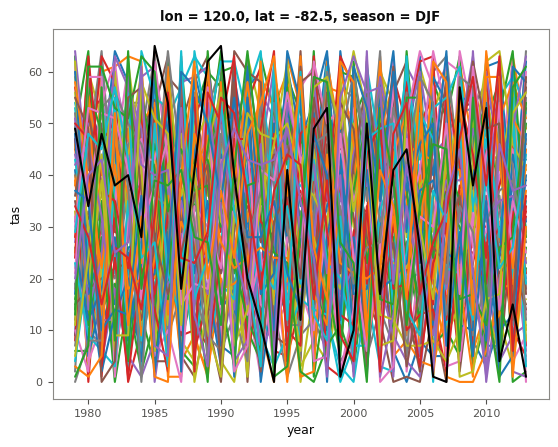

In [112]:
season_pseudo_rank_da.plot(hue='member', add_legend=False);
season_era5_rank_da.plot(color='black')

In [113]:
#(t): 2. and 3. The ranks counted over the years, on the same N bins
n_season_members = season_members_da.sizes['member']
season_era5_counts_da = ev.leave_one_out_counts(season_era5_rank_da, n_season_members, 'year')
season_pseudo_counts_da = ev.rank_counts(season_pseudo_rank_da, n_season_members, 'year')

In [272]:
model_test = season_members_da.isel(member=slice(0, 8), year=slice(0, 5))
obs_test = season_era5_da.isel(year=slice(0, 5))

In [ ]:
#(t): ERA5's rank among the 8 test members in each of the 5 test years, and the rank bins 0 to N - 1
# obs_rank has no member dim, because ensemble_rank counts the members less than ERA5, so N comes from model_test.
obs_rank = ev.ensemble_rank(model_test, obs_test)
n_members = model_test.sizes['member']
bins = ev._rank_bins(n_members, 'rank')

In [306]:
#(t): Leave out a member less than ERA5, and ERA5's rank drops by one
# Example: 4 members, 3 of them less than ERA5, so ERA5's rank is 3.
# If we leave out one of those 3, ERA5's rank becomes 2.
# This happens for 3 of the 4 members we could leave out, so for this year rank 2 is given 0.75.
# The 0.75 is calculated with obs_rank / n_members.
# To give it to rank 2 only, we compare obs_rank - 1 = 2 with the ranks [0, 1, 2, 3], which gives [0, 0, 1, 0].
# Multiplying 0.75 by this gives [0, 0, 0.75, 0], so rank 2 has 0.75 and the other ranks have 0.
# Each year has its own values like this, and they are summed over the years at the end.
leave_out_less_da = (obs_rank / n_members) * (obs_rank - 1 == bins)


In [307]:
#(t): Leave out a member greater than ERA5, and ERA5's rank stays the same
# Same example: 4 members, 3 of them less than ERA5, so 1 is greater than ERA5 and ERA5's rank is 3.
# If we leave out the one that is greater, ERA5 is still greater than 3 members, so its rank stays 3.
# This happens for 1 of the 4 members we could leave out, so for this year rank 3 is given 0.25.
# The 0.25 is calculated with (n_members - obs_rank) / n_members, which is (4 - 3) / 4.
# To give it to rank 3 only, we compare obs_rank = 3 with the ranks [0, 1, 2, 3], which gives [0, 0, 0, 1].
# Multiplying 0.25 by this gives [0, 0, 0, 0.25], so rank 3 has 0.25 and the other ranks have 0.
leave_out_greater_da = ((n_members - obs_rank) / n_members) * (obs_rank == bins)
leave_out_greater_da

In [313]:
#(t): Both cases together, for each year
# In the example, leave_out_less_da is [0, 0, 0.75, 0] and leave_out_greater_da is [0, 0, 0, 0.25].
# Adding them gives [0, 0, 0.75, 0.25] for this year, which adds up to 1, so each year still counts once.
yearly_counts_da = leave_out_less_da + leave_out_greater_da
yearly_counts_da

<xarray.DataArray (year: 5, rank: 8)> Size: 320B
0.0 0.0 0.0 0.0 0.0 0.0 0.0 1.0 0.0 ... 0.0 0.0 0.0 0.375 0.625 0.0 0.0 0.0 0.0
Coordinates:
    lon      float64 8B 120.0
    lat      float64 8B -82.5
    season   <U3 12B 'DJF'
  * year     (year) int64 40B 1979 1980 1981 1982 1983
  * rank     (rank) int64 64B 0 1 2 3 4 5 6 7

In [314]:
#(t): Summed over the years
# Example: the year above gives [0, 0, 0.75, 0.25], and a year where ERA5 is less than all 4 members gives [1, 0, 0, 0].
# Summing these two years gives [1, 0, 0.75, 0.25].
# Summed over every year, this is ERA5's histogram on the same ranks as the pseudo-observations.
counts_da = yearly_counts_da.sum('year')

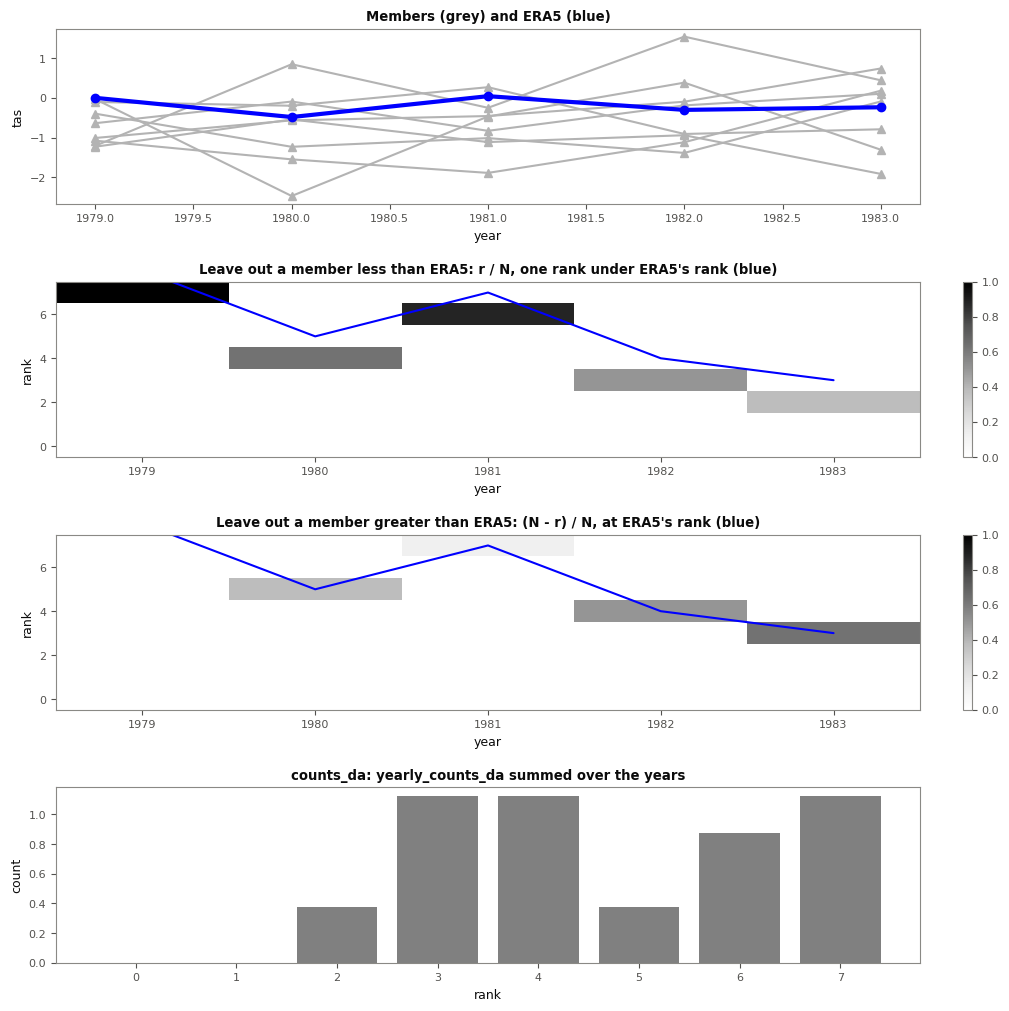

In [315]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(10, 10), layout='constrained')

model_test.plot(ax=ax1, hue='member', add_legend=False, color='0.7', marker='^')
obs_test.plot(ax=ax1, color='blue', linewidth=3, marker='o')
ax1.set_title('Members (grey) and ERA5 (blue)')

leave_out_less_da.plot(ax=ax2, x='year', y='rank', cmap='Greys', vmin=0, vmax=1)
obs_rank.plot(ax=ax2, color='blue')
ax2.set(title="Leave out a member less than ERA5: r / N, one rank under ERA5's rank (blue)", ylabel='rank')

leave_out_greater_da.plot(ax=ax3, x='year', y='rank', cmap='Greys', vmin=0, vmax=1)
obs_rank.plot(ax=ax3, color='blue')
ax3.set(title="Leave out a member greater than ERA5: (N - r) / N, at ERA5's rank (blue)", ylabel='rank')

ax4.bar(counts_da['rank'], counts_da, color='0.5')
ax4.set(title='counts_da: yearly_counts_da summed over the years', xlabel='rank', ylabel='count');

In [ ]:
obs_rank.isel(year=0).values

In [ ]:
leave_out_greater_da.isel(year=0).plot()
leave_out_less_da.isel(year=0).plot()

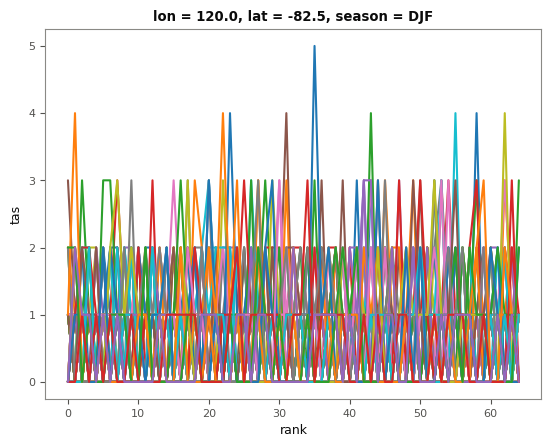

In [114]:
season_pseudo_counts_da.plot(hue='member', add_legend=False);

In [115]:
#(t): 4. Each histogram summarised
season_era5_summary_ds = ev.rank_statistics(season_era5_counts_da)
season_pseudo_summary_ds = ev.rank_statistics(season_pseudo_counts_da)

**How `ev.rank_statistics` gets the dispersion**, step by step on ERA5's histogram (`season_era5_counts_da`), and then the rank trend, the other summary the test locates.

In [ ]:
#(t): The share of the years in each rank
era5_frequency_da = season_era5_counts_da / season_era5_counts_da.sum('rank')

In [ ]:
#(t): Each rank scaled to 0-1: rank r of 0 to M becomes r / M, so histograms of every ensemble size can be compared
# Example: 4 ranks (M = 3) become [0, 1/3, 2/3, 1].
n_top = season_era5_counts_da.sizes['rank'] - 1
scaled_rank_da = season_era5_counts_da['rank'] / n_top

In [ ]:
#(t): ERA5's mean scaled rank: 0.5 when ERA5 sits in the middle of the members on average
# Example: a flat histogram on 4 ranks has the shares [0.25, 0.25, 0.25, 0.25], so its mean is 0.25 * (0 + 1/3 + 2/3 + 1) = 0.5.
era5_mean_rank_da = (era5_frequency_da * scaled_rank_da).sum('rank')

In [ ]:
#(t): How spread out ERA5's scaled ranks are about that mean: their variance
# In the flat example the ranks are 0.5, 1/6, 1/6 and 0.5 from the mean, so the variance is
# 0.25 * (0.25 + 0.028 + 0.028 + 0.25) = 0.139.
# A U shape, [0.5, 0, 0, 0.5], has every year 0.5 from the mean, so its variance is 0.25.
# A dome, [0, 0.5, 0.5, 0], has every year 1/6 from the mean, so its variance is 0.028.
era5_variance_da = (era5_frequency_da * (scaled_rank_da - era5_mean_rank_da) ** 2).sum('rank')

In [ ]:
#(t): The variance a flat histogram on the same ranks has, (M + 2) / (12 M)
# With M = 3 this is 5 / 36 = 0.139, the variance of the flat example.
flat_variance = (n_top + 2) / (12 * n_top)

In [ ]:
#(t): The dispersion: ERA5's variance over the flat histogram's
# The U shape gives 0.25 / 0.139 = 1.8, more than 1: ERA5 is too often beyond the members, so the model's spread is too small.
# The dome gives 0.028 / 0.139 = 0.2, less than 1: ERA5 is too rarely near the edges, so the model's spread is too large.
era5_dispersion_da = era5_variance_da / flat_variance

In [ ]:
#(t): Check: the steps against ev.rank_statistics (difference: 0)
float(abs(era5_dispersion_da - season_era5_summary_ds['dispersion']))

In [ ]:
#(t): The dispersion step by step: a) ERA5's histogram, the share of the years in each scaled rank (bars), a flat one
#(t): (dashed) and ERA5's mean scaled rank (blue); b) each rank's part of the variance, share x (scaled rank - mean)²,
#(t): ERA5's (bars) and a flat histogram's (line)
era5_parts_da = era5_frequency_da * (scaled_rank_da - era5_mean_rank_da) ** 2
flat_parts_da = (1 / (n_top + 1)) * (scaled_rank_da - 0.5) ** 2
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, layout='constrained')
ax1.bar(scaled_rank_da, era5_frequency_da, width=1 / (n_top + 1), color='0.6')
ax1.axhline(1 / (n_top + 1), color='k', ls='--', lw=1)
ax1.axvline(float(era5_mean_rank_da), color='blue')
ax1.set(title=f"a) ERA5's histogram (bars), a flat one (dashed), its mean scaled rank {float(era5_mean_rank_da):.2f} (blue)",
        ylabel='share of the years')
ax2.bar(scaled_rank_da, era5_parts_da, width=1 / (n_top + 1), color='0.6')
ax2.step(scaled_rank_da, flat_parts_da, where='mid', color='k')
ax2.set(title=f"b) Each rank's part of the variance: ERA5's add up to {float(era5_variance_da):.3f}, a flat histogram's "
              f"to {flat_variance:.3f}, so the dispersion is {float(era5_dispersion_da):.2f}",
        xlabel='scaled rank', ylabel='share x (rank - mean)²');

In [ ]:
#(t): The rank trend: ERA5's rank scaled to 0-1 as if it were ranked against N - 1 members, as a pseudo-observation is
# ERA5 is ranked against N members, so its rank runs from 0 to N, but a pseudo-observation's runs from 0 to N - 1.
# Example: 4 members, 3 of them less than ERA5. Leaving out one of those 3 gives rank 2, and leaving out the other one
# gives rank 3, so among 3 members ERA5's rank is 2 three times in 4 and 3 once: on average 0.75 * 2 + 0.25 * 3 = 2.25.
# Scaled by the highest rank, 3, that is 0.75, which is 3 / 4: in general r / N.
season_era5_scaled_da = season_era5_rank_da / n_season_members

In [ ]:
#(t): ... and a pseudo-observation's rank r of 0 to N - 1, scaled by its highest rank
season_pseudo_scaled_da = season_pseudo_rank_da / (n_season_members - 1)

In [ ]:
#(t): Their trends through the years, per decade (ev.trend): a rank that drifts down means ERA5 warms more slowly than
#(t): the members
season_era5_rank_trend_da = ev.trend(season_era5_scaled_da)
season_pseudo_rank_trend_da = ev.trend(season_pseudo_scaled_da)

In [ ]:
#(t): Where ERA5's rank trend falls among the pseudo-observations'
season_rank_trend_test_ds = ev.locate(season_pseudo_rank_trend_da, season_era5_rank_trend_da)

In [116]:
season_pseudo_summary_ds

<xarray.Dataset> Size: 3kB
Dimensions:     (member: 65)
Coordinates:
    lon         float64 8B 120.0
    lat         float64 8B -82.5
    season      <U3 12B 'DJF'
  * member      (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
Data variables:
    below       (member) float64 520B 2.857 0.0 2.857 2.857 ... 5.714 0.0 0.0
    above       (member) float64 520B 2.857 0.0 0.0 0.0 ... 0.0 5.714 0.0 0.0
    outside     (member) float64 520B 5.714 0.0 2.857 2.857 ... 11.43 0.0 0.0
    mean_rank   (member) float64 520B 0.5013 0.4996 0.5 ... 0.4951 0.4996 0.5228
    dispersion  (member) float64 520B 1.217 0.9399 1.066 ... 1.249 0.7319 0.9432

In [117]:
#(t): 5. Where ERA5's dispersion falls among the pseudo-observations'
season_dispersion_test_ds = ev.locate(season_pseudo_summary_ds['dispersion'], season_era5_summary_ds['dispersion'])

In [118]:
season_dispersion_test_ds

<xarray.Dataset> Size: 1kB
Dimensions:     (member: 65)
Coordinates:
    lon         float64 8B 120.0
    lat         float64 8B -82.5
    season      <U3 12B 'DJF'
  * member      (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
Data variables:
    era5        float64 8B 1.164
    members     (member) float64 520B 1.217 0.9399 1.066 ... 1.249 0.7319 0.9432
    lower       float64 8B 0.7748
    median      float64 8B 0.979
    upper       float64 8B 1.261
    percentile  float64 8B 76.92
    pvalue      float64 8B 0.4848
    verdict     float64 8B 0.0
    testable    float64 8B 1.0

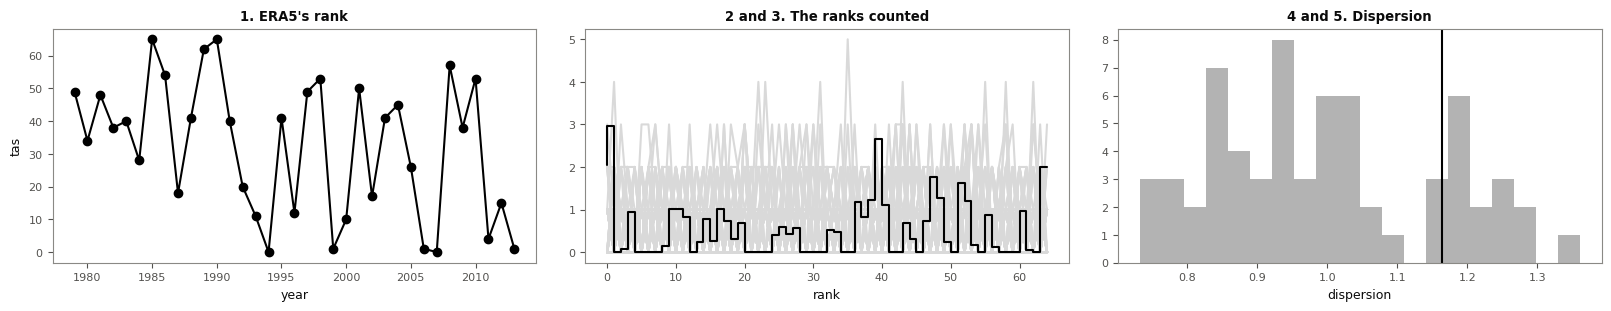

In [119]:
#(t): Quick look: the steps on EXAMPLE_MODEL's anomalies in DJF. ERA5's rank each year (1); the ranks counted,
#(t): ERA5's (black) and each pseudo-observation's (grey) (2 and 3); the dispersions, ERA5's (black) among the
#(t): pseudo-observations' (4 and 5)
fig, axes = plt.subplots(1, 3, figsize=(16, 3), layout='constrained')
season_era5_rank_da.plot(ax=axes[0], marker='o', color='k')
axes[0].set_title("1. ERA5's rank")
season_pseudo_counts_da.plot.line(ax=axes[1], x='rank', hue='member', add_legend=False, color='0.85')
season_era5_counts_da.plot.step(ax=axes[1], color='k')
axes[1].set_title('2 and 3. The ranks counted')
season_pseudo_summary_ds['dispersion'].plot.hist(ax=axes[2], bins=20, color='0.7')
axes[2].axvline(float(season_era5_summary_ds['dispersion']), color='k')
axes[2].set_title('4 and 5. Dispersion');

In [120]:
#(t): The same through ev.rank_histogram_test, which treats the raw values itself and tests every summary
anatomy_result_ds = ev.rank_histogram_test(historical_point_tree[EXAMPLE_MODEL]['historical']['tas'].sel(season='DJF'),
                                           era5_point_da.sel(season='DJF'), 'anomaly')
anatomy_result_ds

<xarray.Dataset> Size: 59kB
Dimensions:           (statistic: 6, member: 65, rank: 65, year: 35)
Coordinates:
    lon               float64 8B 120.0
    lat               float64 8B -82.5
    season            <U3 12B 'DJF'
  * member            (member) object 520B 'r10i1p1f1' ... 'r9i1p2f1'
  * statistic         (statistic) <U10 240B 'dispersion' ... 'rank_trend'
    label             (statistic) <U17 408B 'Rank dispersion' ... 'Rank trend'
    units             (statistic) <U7 168B '' '%' '%' '%' '' '/decade'
    treatment         (statistic) <U7 168B 'anomaly' 'anomaly' ... 'anomaly'
  * rank              (rank) int64 520B 0 1 2 3 4 5 6 7 ... 58 59 60 61 62 63 64
  * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
Data variables: (12/13)
    era5              (statistic) float64 48B 1.164 11.56 ... 0.4954 -0.1176
    members           (statistic, member) float64 3kB 1.217 0.9399 ... 0.0105
    lower             (statistic) float64 48B 0.7748 0.0 0.0 0.0 0.4836 -0.09545
    median            (statistic) float64 48B 0.979 2.857 ... 0.4991 -0.003151
    upper             (statistic) float64 48B 1.261 8.0 5.714 ... 0.519 0.07656
    percentile        (statistic) float64 48B 76.92 100.0 98.46 ... 38.46 1.538
    ...                ...
    verdict           (statistic) float64 48B 0.0 1.0 1.0 0.0 0.0 -1.0
    testable          (statistic) float64 48B 1.0 1.0 1.0 1.0 1.0 1.0
    obs_frequency     (rank) float64 520B 5.846 8.44 0.0 ... 0.1319 0.0 5.714
    pseudo_frequency  (rank, member) float64 34kB 2.857 0.0 2.857 ... 0.0 0.0
    obs_rank          (year) float64 280B 0.7538 0.5231 ... 0.2308 0.01538
    pseudo_rank       (member, year) float64 18kB 0.2656 0.9062 ... 0.5938
Attributes: (4)

In [121]:
#(t): Check: both give the same dispersion test
check_variables = ['era5', 'percentile', 'pvalue', 'verdict']
pd.DataFrame({'step by step': season_dispersion_test_ds[check_variables].to_pandas(),
              'ev.rank_histogram_test': anatomy_result_ds.sel(statistic='dispersion')[check_variables].to_pandas()})

,step by step,ev.rank_histogram_test
era5,1.164070,1.164070
percentile,76.923077,76.923077
pvalue,0.484848,0.484848
verdict,0.000000,0.000000


In [ ]:
#(t): Check: the rank trend step by step against ev.rank_histogram_test's (difference of ERA5's percentile: 0)
float(abs(season_rank_trend_test_ds['percentile'] - anatomy_result_ds.sel(statistic='rank_trend')['percentile']))

In [122]:
#(t): The anomalies, together for plot_01's figure of the method
rank_anatomy_ds = xr.Dataset({'members': season_members_da, 'era5': season_era5_da})

In [123]:
#(t): Saved for plot_01
rank_anatomy_data_path = RESULTS_DIR / 'rank_anatomy_data.zarr'
rank_anatomy_ds.to_zarr(rank_anatomy_data_path, mode='w')
rank_anatomy_data_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/rank_anatomy_data.zarr')

In [124]:
#(t): ... and the test
rank_anatomy_test_path = RESULTS_DIR / 'rank_anatomy_test.zarr'
anatomy_result_ds.to_zarr(rank_anatomy_test_path, mode='w')
rank_anatomy_test_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/rank_anatomy_test.zarr')

### Every model

The headline histograms pool the four seasons (four times the samples); the scorecard uses one per season.

In [125]:
#(t): Raw values, the four seasons pooled: ev.rank_histogram_test on each model's members (it needs each model's own
#(t): number of members), against ERA5
raw_ranks_tree = xr.DataTree.from_dict({
    node.path: ev.rank_histogram_test(node['tas'], era5_point_da, 'raw', pool_dims=('year', 'season'))
    for node in historical_point_tree.leaves
})

In [126]:
#(t): Anomalies, the four seasons pooled
anomaly_ranks_tree = xr.DataTree.from_dict({
    node.path: ev.rank_histogram_test(node['tas'], era5_point_da, 'anomaly', pool_dims=('year', 'season'))
    for node in historical_point_tree.leaves
})
anomaly_ranks_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   └── Group: /CanESM5/historical
│           Dimensions:           (statistic: 6, member: 65, rank: 65, season: 4, year: 35)
│           Coordinates:
│               lon               float64 8B 120.0
│               lat               float64 8B -82.5
│             * member            (member) object 520B 'r10i1p1f1' ... 'r9i1p2f1'
│             * statistic         (statistic) <U10 240B 'dispersion' ... 'rank_trend'
│               label             (statistic) <U17 408B 'Rank dispersion' ... 'Rank trend'
│               units             (statistic) <U7 168B '' '%' '%' '%' '' '/decade'
│               treatment         (statistic) <U7 168B 'anomaly' 'anomaly' ... 'anomaly'
│             * rank              (rank) int64 520B 0 1 2 3 4 5 6 7 ... 58 59 60 61 62 63 64
│             * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
│           Data variables: (12/13)
│               era5              (statistic) float64 48B 1.047 5.077 ... 0.5015 -0.08095
│               members           (statistic, member) float64 3kB 1.037 1.058 ... 0.002746
│               lower             (statistic) float64 48B 0.8815 0.7143 ... 0.49 -0.04405
│               median            (statistic) float64 48B 0.9985 2.857 ... 0.5 0.002746
│               upper             (statistic) float64 48B 1.096 6.143 ... 0.5098 0.0373
│               percentile        (statistic) float64 48B 72.31 93.85 84.62 93.85 56.92 0.0
│               ...                ...
│               verdict           (statistic) float64 48B 0.0 0.0 0.0 0.0 0.0 -1.0
│               testable          (statistic) float64 48B 1.0 1.0 1.0 1.0 1.0 1.0
│               obs_frequency     (rank) float64 520B 2.209 4.264 1.418 ... 0.7473 2.868
│               pseudo_frequency  (rank, member) float64 34kB 2.143 2.857 ... 0.7143 0.0
│               obs_rank          (year, season) float64 1kB 0.7538 0.2923 ... 0.9846
│               pseudo_rank       (member, year, season) float64 73kB 0.2656 ... 0.8906
│           Attributes: (4)
├── Group: /GISS-E2-1-G
│   └── Group: /GISS-E2-1-G/historical
│           Dimensions:           (statistic: 6, member: 63, rank: 63, season: 4, year: 35)
│           Coordinates:
│               lon               float64 8B 120.0
│               lat               float64 8B -82.5
│             * member            (member) object 504B 'r10i1p1f1' ... 'r9i1p5f1'
│             * statistic         (statistic) <U10 240B 'dispersion' ... 'rank_trend'
│               label             (statistic) <U17 408B 'Rank dispersion' ... 'Rank trend'
│               units             (statistic) <U7 168B '' '%' '%' '%' '' '/decade'
│               treatment         (statistic) <U7 168B 'anomaly' 'anomaly' ... 'anomaly'
│             * rank              (rank) int64 504B 0 1 2 3 4 5 6 7 ... 56 57 58 59 60 61 62
│             * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
│           Data variables: (12/13)
│               era5              (statistic) float64 48B 1.261 2.914 ... 0.4883 -0.02108
│               members           (statistic, member) float64 3kB 0.06908 ... -0.04369
│               lower             (statistic) float64 48B 0.06908 0.0 0.0 0.0 0.421 -0.04369
│               median            (statistic) float64 48B 1.316 3.571 ... 0.4969 0.001864
│               upper             (statistic) float64 48B 1.438 7.071 ... 0.5952 0.07066
│               percentile        (statistic) float64 48B 39.68 46.03 76.19 41.27 30.16 38.1
│               ...                ...
│               verdict           (statistic) float64 48B 0.0 0.0 0.0 0.0 0.0 0.0
│               testable          (statistic) float64 48B 1.0 1.0 1.0 1.0 1.0 1.0
│               obs_frequency     (rank) float64 504B 2.154 0.771 2.143 ... 2.88 0.7596
│  

In [127]:
#(t): Detrended anomalies, the four seasons pooled
detrended_ranks_tree = xr.DataTree.from_dict({
    node.path: ev.rank_histogram_test(node['tas'], era5_point_da, 'detrended', pool_dims=('year', 'season'))
    for node in historical_point_tree.leaves
})

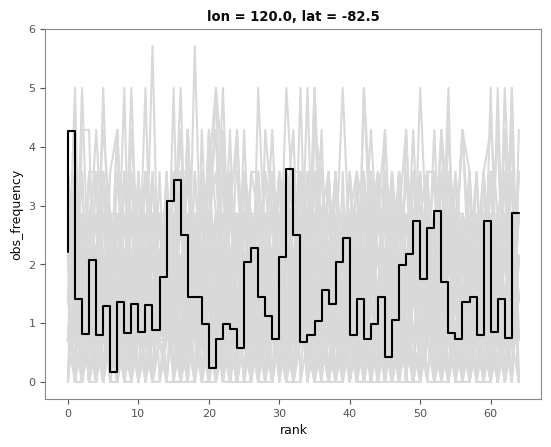

In [128]:
#(t): Quick look: EXAMPLE_MODEL's histogram of anomalies (bars: ERA5; grey: each pseudo-observation's)
anomaly_ranks_ds = anomaly_ranks_tree[EXAMPLE_MODEL]['historical'].to_dataset()
anomaly_ranks_ds['pseudo_frequency'].plot.line(x='rank', hue='member', add_legend=False, color='0.85')
anomaly_ranks_ds['obs_frequency'].plot.step(color='k');

In [129]:
#(t): One test per season, for the scorecard (without the histograms): anomalies
anomaly_ranks_seasonal_tree = xr.DataTree.from_dict({
    node.path: ev.rank_histogram_test(node['tas'], era5_point_da, 'anomaly', pool_dims=('year',), keep_histograms=False)
    for node in historical_point_tree.leaves
})

In [130]:
#(t): ... and detrended anomalies
detrended_ranks_seasonal_tree = xr.DataTree.from_dict({
    node.path: ev.rank_histogram_test(node['tas'], era5_point_da, 'detrended', pool_dims=('year',),
                                      keep_histograms=False)
    for node in historical_point_tree.leaves
})

In [131]:
#(t): Saved for plot_01
raw_ranks_path = RESULTS_DIR / 'raw_ranks.zarr'
raw_ranks_tree.to_zarr(raw_ranks_path, mode='w')
raw_ranks_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/raw_ranks.zarr')

In [132]:
#(t): Saved for plot_01
anomaly_ranks_path = RESULTS_DIR / 'anomaly_ranks.zarr'
anomaly_ranks_tree.to_zarr(anomaly_ranks_path, mode='w')
anomaly_ranks_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/anomaly_ranks.zarr')

In [133]:
#(t): Saved for plot_01
detrended_ranks_path = RESULTS_DIR / 'detrended_ranks.zarr'
detrended_ranks_tree.to_zarr(detrended_ranks_path, mode='w')
detrended_ranks_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/detrended_ranks.zarr')

## Every Test in One Table

Each test's percentile, verdict and whether it could flag anything, without the members, so every model fits in one Dataset on (model, statistic, season): for plot_01's scorecard and signal-vs-noise diagram. For the moment test and the other statistics, ERA5's value is placed among each model's members here, at the point (`ev.locate`, gone through step by step in plot_01), from the values notebook calc_03a saved; the rank tests are from above. Both rank tests have a dispersion, so those two are named for their treatment.

In [ ]:
#(t): Every member's mean at every grid point (/<model>/historical), and ERA5's, as notebook calc_03a saved them
historical_mean_tree = xr.open_datatree(RESULTS_DIR / 'historical_mean.zarr', engine='zarr')
era5_mean_da = xr.open_zarr(RESULTS_DIR / 'era5_mean.zarr')[VARIABLE.name].load()

In [ ]:
#(t): Every member's standard deviation (detrended) at every grid point (/<model>/historical), and ERA5's, as notebook calc_03a saved them
historical_std_tree = xr.open_datatree(RESULTS_DIR / 'historical_std.zarr', engine='zarr')
era5_std_da = xr.open_zarr(RESULTS_DIR / 'era5_std.zarr')[VARIABLE.name].load()

In [ ]:
#(t): Every member's skewness (detrended) at every grid point (/<model>/historical), and ERA5's, as notebook calc_03a saved them
historical_skewness_tree = xr.open_datatree(RESULTS_DIR / 'historical_skewness.zarr', engine='zarr')
era5_skewness_da = xr.open_zarr(RESULTS_DIR / 'era5_skewness.zarr')[VARIABLE.name].load()

In [ ]:
#(t): Every member's excess kurtosis (detrended) at every grid point (/<model>/historical), and ERA5's, as notebook calc_03a saved them
historical_kurtosis_tree = xr.open_datatree(RESULTS_DIR / 'historical_kurtosis.zarr', engine='zarr')
era5_kurtosis_da = xr.open_zarr(RESULTS_DIR / 'era5_kurtosis.zarr')[VARIABLE.name].load()

In [ ]:
#(t): Every member's trend at every grid point (/<model>/historical), and ERA5's, as notebook calc_03a saved them
historical_trend_tree = xr.open_datatree(RESULTS_DIR / 'historical_trend.zarr', engine='zarr')
era5_trend_da = xr.open_zarr(RESULTS_DIR / 'era5_trend.zarr')[VARIABLE.name].load()

In [ ]:
#(t): Every member's width (detrended) at every grid point (/<model>/historical), and ERA5's, as notebook calc_03a saved them
historical_width_tree = xr.open_datatree(RESULTS_DIR / 'historical_width.zarr', engine='zarr')
era5_width_da = xr.open_zarr(RESULTS_DIR / 'era5_width.zarr')[VARIABLE.name].load()

In [ ]:
#(t): Every member's lower tail (detrended) at every grid point (/<model>/historical), and ERA5's, as notebook calc_03a saved them
historical_lower_tail_tree = xr.open_datatree(RESULTS_DIR / 'historical_lower_tail.zarr', engine='zarr')
era5_lower_tail_da = xr.open_zarr(RESULTS_DIR / 'era5_lower_tail.zarr')[VARIABLE.name].load()

In [ ]:
#(t): Every member's upper tail (detrended) at every grid point (/<model>/historical), and ERA5's, as notebook calc_03a saved them
historical_upper_tail_tree = xr.open_datatree(RESULTS_DIR / 'historical_upper_tail.zarr', engine='zarr')
era5_upper_tail_da = xr.open_zarr(RESULTS_DIR / 'era5_upper_tail.zarr')[VARIABLE.name].load()

In [ ]:
#(t): The mean at the point: where ERA5's falls among each model's members (ev.locate), /<model>/historical
mean_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node[VARIABLE.name].sel(SAMPLE_LAT_LON), era5_mean_da.sel(SAMPLE_LAT_LON))
    for node in historical_mean_tree.leaves
})

In [ ]:
#(t): The standard deviation (detrended) at the point: where ERA5's falls among each model's members (ev.locate), /<model>/historical
std_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node[VARIABLE.name].sel(SAMPLE_LAT_LON), era5_std_da.sel(SAMPLE_LAT_LON))
    for node in historical_std_tree.leaves
})

In [ ]:
#(t): The skewness (detrended) at the point: where ERA5's falls among each model's members (ev.locate), /<model>/historical
skewness_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node[VARIABLE.name].sel(SAMPLE_LAT_LON), era5_skewness_da.sel(SAMPLE_LAT_LON))
    for node in historical_skewness_tree.leaves
})

In [ ]:
#(t): The excess kurtosis (detrended) at the point: where ERA5's falls among each model's members (ev.locate), /<model>/historical
kurtosis_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node[VARIABLE.name].sel(SAMPLE_LAT_LON), era5_kurtosis_da.sel(SAMPLE_LAT_LON))
    for node in historical_kurtosis_tree.leaves
})

In [ ]:
#(t): The trend at the point: where ERA5's falls among each model's members (ev.locate), /<model>/historical
trend_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node[VARIABLE.name].sel(SAMPLE_LAT_LON), era5_trend_da.sel(SAMPLE_LAT_LON))
    for node in historical_trend_tree.leaves
})

In [ ]:
#(t): The width (detrended) at the point: where ERA5's falls among each model's members (ev.locate), /<model>/historical
width_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node[VARIABLE.name].sel(SAMPLE_LAT_LON), era5_width_da.sel(SAMPLE_LAT_LON))
    for node in historical_width_tree.leaves
})

In [ ]:
#(t): The lower tail (detrended) at the point: where ERA5's falls among each model's members (ev.locate), /<model>/historical
lower_tail_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node[VARIABLE.name].sel(SAMPLE_LAT_LON), era5_lower_tail_da.sel(SAMPLE_LAT_LON))
    for node in historical_lower_tail_tree.leaves
})

In [ ]:
#(t): The upper tail (detrended) at the point: where ERA5's falls among each model's members (ev.locate), /<model>/historical
upper_tail_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node[VARIABLE.name].sel(SAMPLE_LAT_LON), era5_upper_tail_da.sel(SAMPLE_LAT_LON))
    for node in historical_upper_tail_tree.leaves
})

In [ ]:
#(t): The eight along a statistic dim, verdicts only (no members), with the values each was worked out on (raw or
#(t): detrended, as the rank tests carry theirs), every model, on (model, experiment, statistic, season)
statistic_verdicts_tree = xr.DataTree.from_dict({
    node.path: xr.concat([node.to_dataset(), std_test_tree[node.path].to_dataset(),
                          skewness_test_tree[node.path].to_dataset(), kurtosis_test_tree[node.path].to_dataset(),
                          trend_test_tree[node.path].to_dataset(), width_test_tree[node.path].to_dataset(),
                          lower_tail_test_tree[node.path].to_dataset(), upper_tail_test_tree[node.path].to_dataset()],
                         dim=xr.Variable('statistic', ['mean', 'std', 'skewness', 'kurtosis', 'trend', 'width',
                                                       'lower_tail', 'upper_tail']))[['percentile', 'verdict', 'testable']]
    for node in mean_test_tree.leaves
})
statistic_verdicts_ds = tree_to_dataset(statistic_verdicts_tree, dims=['model', 'experiment'])
statistic_verdicts_ds = statistic_verdicts_ds.assign_coords(
    treatment=('statistic', ['raw', 'detrended', 'detrended', 'detrended', 'raw', 'detrended', 'detrended', 'detrended']))

In [136]:
#(t): The rank trend and dispersion of the anomalies, verdicts only
anomaly_rank_verdicts_tree = xr.DataTree.from_dict({node.path: node.to_dataset()[['percentile', 'verdict', 'testable']]
                                                    for node in anomaly_ranks_seasonal_tree.leaves})
anomaly_rank_verdicts_ds = tree_to_dataset(anomaly_rank_verdicts_tree, dims=['model', 'experiment'])
anomaly_rank_verdicts_ds = anomaly_rank_verdicts_ds.sel(statistic=['rank_trend', 'dispersion']).drop_vars(['label', 'units'])
anomaly_rank_verdicts_ds = anomaly_rank_verdicts_ds.assign_coords(statistic=['rank_trend', 'dispersion (anomaly)'])

In [137]:
#(t): ... and the dispersion of the detrended anomalies
detrended_rank_verdicts_tree = xr.DataTree.from_dict({node.path: node.to_dataset()[['percentile', 'verdict', 'testable']]
                                                      for node in detrended_ranks_seasonal_tree.leaves})
detrended_rank_verdicts_ds = tree_to_dataset(detrended_rank_verdicts_tree, dims=['model', 'experiment'])
detrended_rank_verdicts_ds = detrended_rank_verdicts_ds.sel(statistic=['dispersion']).drop_vars(['label', 'units'])
detrended_rank_verdicts_ds = detrended_rank_verdicts_ds.assign_coords(statistic=['dispersion (detrended)'])

In [ ]:
#(t): Everything along one statistic dim
eval_table_by_experiment_ds = xr.concat([statistic_verdicts_ds, anomaly_rank_verdicts_ds, detrended_rank_verdicts_ds],
                                        dim='statistic')
eval_table_ds = eval_table_by_experiment_ds.sel(experiment='historical', drop=True)
# Anything opened from a zarr store remembers how long its text was. Saved with that, a longer name such as
# 'dispersion (anomaly)' would be cut short, so it is dropped
eval_table_ds = eval_table_ds.drop_encoding()
#(c): tree_to_dataset leaves the model names as Python objects, which xarray will not put on an axis
eval_table_ds = eval_table_ds.assign_coords(model=eval_table_ds['model'].astype(str),
                                            season=eval_table_ds['season'].astype(str))
eval_table_ds

In [ ]:
#(t): Quick look: ERA5's percentile among each model's members (50: in the middle; 0 or 100: beyond every member)
eval_table_ds['percentile'].sel(season=SEASONS).plot(x='season', y='model', col='statistic', col_wrap=5, vmin=0,
                                                     vmax=100, cmap='RdBu_r');

In [142]:
#(t): Saved for plot_01
eval_table_path = RESULTS_DIR / 'eval_table.zarr'
eval_table_ds.to_zarr(eval_table_path, mode='w')
eval_table_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/eval_table.zarr')

## Toy Ensembles with a Known Answer

The toy ensembles of notebook calc_03a (`ev.simulate_ensemble`, the same seed, so the same ensembles; its quick look draws them), here for the rank-histogram tests and the plume. plot_01 draws them.

In [143]:
#(t): A toy ensemble and pseudo-ERA5 for each scenario, side by side on a scenario dim (all have 50 members)
demo_datasets = []
for settings in ev.SCENARIOS.values():
    demo_members_da, demo_era5_da = ev.simulate_ensemble(seed=3, **settings)
    demo_datasets.append(xr.Dataset({'members': demo_members_da, 'era5': demo_era5_da}))
demo_ds = xr.concat(demo_datasets, dim=xr.Variable('scenario', list(ev.SCENARIOS)))

In [148]:
#(t): The rank-histogram tests, the four seasons pooled: anomalies, and detrended anomalies
demo_anomaly_ranks_ds = ev.rank_histogram_test(demo_ds['members'], demo_ds['era5'], 'anomaly',
                                               pool_dims=('year', 'season'))
demo_detrended_ranks_ds = ev.rank_histogram_test(demo_ds['members'], demo_ds['era5'], 'detrended',
                                                 pool_dims=('year', 'season'))

In [149]:
#(t): The plume of the raw values: the members' quantiles each year, and where pseudo-ERA5 is
demo_plume_ds = ev.ensemble_plume(demo_ds['members'], demo_ds['era5'], 'raw')

In [151]:
#(t): Saved for plot_01
demo_anomaly_ranks_path = RESULTS_DIR / 'demo_anomaly_ranks.zarr'
demo_anomaly_ranks_ds.to_zarr(demo_anomaly_ranks_path, mode='w')
demo_anomaly_ranks_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/demo_anomaly_ranks.zarr')

In [152]:
#(t): Saved for plot_01
demo_detrended_ranks_path = RESULTS_DIR / 'demo_detrended_ranks.zarr'
demo_detrended_ranks_ds.to_zarr(demo_detrended_ranks_path, mode='w')
demo_detrended_ranks_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/demo_detrended_ranks.zarr')

In [153]:
#(t): Saved for plot_01
demo_plume_path = RESULTS_DIR / 'demo_plume.zarr'
demo_plume_ds.to_zarr(demo_plume_path, mode='w')
demo_plume_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/demo_plume.zarr')

## 8. Spatial Evaluation (Suarez-Gutierrez et al., 2021)

The paper's grid-point evaluation (their sections 2.2.2 and 3.2–3.4), at every grid point and season, by `ev.spatial_evaluation`: each year, is ERA5 (in anomalies) below every member, above every member, or in their central 75%? A perfect model puts ERA5 beyond each edge in 100/(N + 1)% of years and in the middle about 75% of the time; the paper flags ≥ 10% below, ≥ 10% above or > 80% in the middle. When the problem years fall (1979–1996 or 1997–2013) then says whether the forced response or the variability is wrong. plot_01 draws the maps.

### Calculate (slow; saves the result)

In [163]:
#(t): The paper's thresholds (10% / 10% / 80%), and the two halves of the record
SPATIAL_THRESHOLDS = 'fixed'
SPATIAL_PERIODS = {'early': slice(1979, 1996), 'late': slice(1997, None)}

In [164]:
#(t): One model: the whole record, each half, and whether a problem is spread evenly over the two (the variability)
#(t): or not (the forced response)
def spatial_evaluation(ds):
    """The paper's grid-point evaluation (ev.spatial_evaluation) of one model's historical members against ERA5.

    Args:
        ds (xr.Dataset): One model's node: tas on (member, year, season, lat, lon), over SATELLITE_YEAR_RANGE.

    Returns:
        xr.Dataset: ev.spatial_evaluation's result over the whole record on (season, lat, lon), with
        period_diagnosis (ev.period_comparison of the two halves, SPATIAL_PERIODS).
    """
    members_da = ds['tas'].load()
    era5_da = era5_seasonal_da.sel(year=SATELLITE_YEAR_RANGE)
    whole_ds = ev.spatial_evaluation(members_da, era5_da, thresholds=SPATIAL_THRESHOLDS)
    early_ds = ev.spatial_evaluation(members_da, era5_da, period=SPATIAL_PERIODS['early'], thresholds=SPATIAL_THRESHOLDS)
    late_ds = ev.spatial_evaluation(members_da, era5_da, period=SPATIAL_PERIODS['late'], thresholds=SPATIAL_THRESHOLDS)
    return whole_ds.assign(period_diagnosis=ev.period_comparison(whole_ds, early_ds, late_ds))

In [165]:
%%time
#(t): Example: EXAMPLE_MODEL
example_spatial_ds = spatial_evaluation(lesfmip_obs_tree[EXAMPLE_MODEL]['historical'].to_dataset())
example_spatial_ds

CPU times: user 1.71 s, sys: 88.7 ms, total: 1.8 s
Wall time: 1.82 s


<xarray.Dataset> Size: 1MB
Dimensions:            (lat: 20, season: 4, lon: 144)
Coordinates:
  * lat                (lat) float64 160B -87.5 -85.0 -82.5 ... -42.5 -40.0
  * season             (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lon                (lon) float64 1kB -180.0 -177.5 -175.0 ... 175.0 177.5
Data variables: (12/16)
    below              (lat, lon, season) float64 92kB 0.0 2.857 ... 5.714 5.714
    above              (lat, lon, season) float64 92kB 0.0 0.0 ... 2.857 5.714
    central            (lat, lon, season) float64 92kB 71.43 68.57 ... 57.14
    below_late         (lat, lon, season) float64 92kB nan 1.0 nan ... 0.5 0.5
    above_late         (lat, lon, season) float64 92kB nan nan 0.0 ... 1.0 0.5
    below_threshold    (lat, lon, season) float64 92kB 10.0 10.0 ... 10.0 10.0
    ...                 ...
    central_flag       (lat, lon, season) float64 92kB 0.0 0.0 0.0 ... 0.0 0.0
    diagnosis          (lat, lon, season) float64 92kB 0.0 0.0 0.0 ... 0.0 0.0
    adequate           (lat, lon, season) float64 92kB 1.0 1.0 1.0 ... 1.0 1.0
    n_years            (lat, lon, season) int64 92kB 35 35 35 35 ... 35 35 35 35
    n_members          int64 8B 65
    period_diagnosis   (lat, lon, season) float64 92kB 0.0 0.0 0.0 ... 0.0 0.0
Attributes: (1)

In [166]:
#(t): Check at the point, by hand: the % of years ERA5's anomaly is below every member's (each series minus its own
#(t): mean over the years), against the example's
point_member_anomaly_da = historical_anomaly_tree[EXAMPLE_MODEL]['historical']['tas']
point_below_da = 100 * (era5_anomaly_da < point_member_anomaly_da.min('member')).mean('year')
float(abs(point_below_da - example_spatial_ds['below'].sel(SAMPLE_LAT_LON)).max())

0.0

**How `ev.spatial_evaluation` works**, step by step at the point (EXAMPLE_MODEL, DJF): steps 3 to 7 of the paper's evaluation, then step 8, `ev.period_comparison`.

In [ ]:
#(t): EXAMPLE_MODEL's members' DJF anomalies at the point, and ERA5's
spatial_members_da = historical_anomaly_tree[EXAMPLE_MODEL]['historical']['tas'].sel(season='DJF')
spatial_era5_da = era5_anomaly_da.sel(season='DJF')

In [ ]:
#(t): Each year, is ERA5 less than every member, or greater than every member?
# Example: in a year whose members run from -1.2 to 0.9 °C, ERA5 at -1.5 is less than every member, and ERA5 at 0.3 is neither.
spatial_below_da = spatial_era5_da < spatial_members_da.min('member')
spatial_above_da = spatial_era5_da > spatial_members_da.max('member')

In [ ]:
#(t): Each year, is ERA5 inside the members' central 75%, from their 12.5th to their 87.5th percentile (ev.CENTRAL_RANGE)?
spatial_range_da = spatial_members_da.quantile(list(ev.CENTRAL_RANGE), dim='member')
spatial_central_da = ((spatial_era5_da >= spatial_range_da.isel(quantile=0, drop=True))
                      & (spatial_era5_da <= spatial_range_da.isel(quantile=1, drop=True)))

In [ ]:
#(t): The % of the years of each
# A perfect model puts ERA5 less than every one of N members in 100 / (N + 1) % of the years: 1.5% for 65 members.
# The paper flags a point with 10% or more of the years less than every member (ev.EDGE_THRESHOLD), 10% or more greater
# than every member, or more than 80% inside the central 75% (ev.CENTRAL_THRESHOLD), where a perfect model gives 75%.
spatial_percent_ds = 100 * xr.Dataset({'below': spatial_below_da, 'above': spatial_above_da,
                                       'central': spatial_central_da}).mean('year')

In [ ]:
#(t): When the edge years fall: the share of them in the second half of the record
# Example: 6 years less than every member, 5 of them after the middle of the record: a late share of 5 / 6 = 0.83.
# At least 2 / 3 late (ev.TIMING_SHARE) counts as mostly late. ERA5 less than the members mostly late means the model warms
# too much: the anomalies are from each series' own mean, so a model that warms too fast is too warm late and too cold early.
spatial_years_da = spatial_era5_da['year']
spatial_late_da = spatial_years_da > (spatial_years_da.min() + spatial_years_da.max()) / 2
spatial_below_late = float(spatial_below_da.where(spatial_late_da, 0).sum() / spatial_below_da.sum())
spatial_above_late = float(spatial_above_da.where(spatial_late_da, 0).sum() / spatial_above_da.sum())

In [ ]:
#(t): Check: the steps against ev.spatial_evaluation at the point (example_spatial_ds, above), and its diagnosis
# The diagnosis (ev.DIAGNOSES) applies these rules in turn, each later one overriding the ones before:
# 4 "too much variability": more than 80% of the years inside the central 75%;
# 5 "one tail too short": 10% or more of the years beyond one edge only;
# 3 "too little variability": 10% or more beyond both edges;
# 2 "warms too little" and 1 "warms too much": the edge years mostly in one half, as a wrong forced response puts them.
# With both edges beyond their limits, both must point the same way: for 1, greater than the members early and less late.
# 0 "adequate" is what is left.
spatial_check_ds = example_spatial_ds.sel(SAMPLE_LAT_LON).sel(season='DJF')
pd.DataFrame({'step by step': [float(spatial_percent_ds['below']), float(spatial_percent_ds['above']),
                               float(spatial_percent_ds['central']), spatial_below_late, spatial_above_late, np.nan],
              'ev.spatial_evaluation': [float(spatial_check_ds[name]) for name in
                                        ['below', 'above', 'central', 'below_late', 'above_late', 'diagnosis']]},
             index=['below', 'above', 'central', 'below_late', 'above_late', 'diagnosis'])

In [ ]:
#(t): The grid-point evaluation step by step at the point (EXAMPLE_MODEL, DJF): a) the members' range (light) and central
#(t): 75% (dark), and ERA5 (blue); b) each year, ERA5 less than every member, greater than every member, or inside the
#(t): central 75% (black); c) the % of the years of each, and the paper's limits (black). Dashed: the middle of the record
spatial_middle = (int(spatial_years_da.min()) + int(spatial_years_da.max())) / 2
spatial_flags_arr = np.stack([spatial_below_da.values, spatial_above_da.values, spatial_central_da.values]).astype(float)
spatial_names = ['less than every member', 'greater than every member', 'inside the central 75%']
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 9), layout='constrained')
ax1.fill_between(spatial_years_da, spatial_members_da.min('member'), spatial_members_da.max('member'), color='0.9')
ax1.fill_between(spatial_years_da, spatial_range_da.isel(quantile=0), spatial_range_da.isel(quantile=1), color='0.7')
ax1.plot(spatial_years_da, spatial_era5_da, color='blue', marker='o', linewidth=2)
ax1.set(title="a) The members' range (light) and central 75% (dark), and ERA5 (blue): anomalies", ylabel=VARIABLE.units)
ax2.imshow(spatial_flags_arr, aspect='auto', cmap='Greys', vmin=0, vmax=1, interpolation='none',
           extent=(float(spatial_years_da[0]) - 0.5, float(spatial_years_da[-1]) + 0.5, 2.5, -0.5))
ax2.set_yticks([0, 1, 2], spatial_names)
ax2.set_title('b) Each year: ERA5 less than every member, greater than every member, or inside the central 75% (black)')
for ax in (ax1, ax2):
    ax.axvline(spatial_middle, color='k', ls='--', lw=1)
ax3.bar(spatial_names, [float(spatial_percent_ds[name]) for name in ['below', 'above', 'central']], color='0.6')
ax3.hlines([ev.EDGE_THRESHOLD, ev.EDGE_THRESHOLD, ev.CENTRAL_THRESHOLD], [-0.4, 0.6, 1.6], [0.4, 1.4, 2.4], color='k')
ax3.set(title="c) % of the years of each, and the paper's limits (black)", ylabel='% of the years');

In [ ]:
#(t): Step 8 (ev.period_comparison) at the point: each half of the record evaluated on its own
# The anomalies stay those of the whole record; each half is then counted on its own, as spatial_evaluation does with period=.
spatial_early_ds = ev.spatial_evaluation(historical_point_tree[EXAMPLE_MODEL]['historical']['tas'], era5_point_da,
                                         period=SPATIAL_PERIODS['early'], thresholds=SPATIAL_THRESHOLDS).sel(season='DJF')
spatial_late_ds = ev.spatial_evaluation(historical_point_tree[EXAMPLE_MODEL]['historical']['tas'], era5_point_da,
                                        period=SPATIAL_PERIODS['late'], thresholds=SPATIAL_THRESHOLDS).sel(season='DJF')

In [ ]:
#(t): How many years ERA5 is beyond each edge, and inside the central 75%, in each half: the % back to a count of years
# Example: 18 early years with 16.7% of them greater than every member is 3 years.
above_early = np.round(float(spatial_early_ds['above']) * float(spatial_early_ds['n_years']) / 100)
above_late = np.round(float(spatial_late_ds['above']) * float(spatial_late_ds['n_years']) / 100)
below_early = np.round(float(spatial_early_ds['below']) * float(spatial_early_ds['n_years']) / 100)
below_late = np.round(float(spatial_late_ds['below']) * float(spatial_late_ds['n_years']) / 100)
central_early = np.round(float(spatial_early_ds['central']) * float(spatial_early_ds['n_years']) / 100)
central_late = np.round(float(spatial_late_ds['central']) * float(spatial_late_ds['n_years']) / 100)

In [ ]:
#(t): Do the edge years fit a wrong forced response? A binomial test of how they split between the halves
# Too much warming puts ERA5 greater than the members early and less than them late: those years fit it.
# Example: 18 early and 17 late years, ERA5 greater than every member in 3 years and less than every member in 5.
# If the edge years were spread evenly, a year greater would be early 18 / 35 of the time and a year less would be late
# 17 / 35 of the time, so (3 * 18 + 5 * 17) / (35 * 8) = 0.50 of the 8 would fit by chance.
# If all 8 fit (3 greater early and 5 less late), the two-sided binomial p-value is about 2 * 0.5 ** 8 = 0.008. That is
# less than 0.1 (ev.PERIOD_ALPHA), so the problem changes between the halves: it points at the forced response.
n_early, n_late = float(spatial_early_ds['n_years']), float(spatial_late_ds['n_years'])
n_edge = above_early + above_late + below_early + below_late
expected_share = ((above_early + above_late) * n_early + (below_early + below_late) * n_late) / ((n_early + n_late) * n_edge)
edge_pvalue = float(ev._binomial_pvalue(above_early + below_late, n_edge, expected_share))

In [ ]:
#(t): ... and do the years inside the central 75% split between the halves in proportion to their lengths?
central_pvalue = float(ev._binomial_pvalue(central_late, central_early + central_late, n_late / (n_early + n_late)))

In [ ]:
#(t): Check: the period diagnosis at the point (ev.PERIOD_DIAGNOSES): 0 no problem over the whole record, 1 the same problem
#(t): in both halves (the variability), 2 a problem whose test above has a p-value less than 0.1 (the forced response)
pd.Series({'edge p-value': edge_pvalue, 'central p-value': central_pvalue,
           'period_diagnosis': float(spatial_check_ds['period_diagnosis'])})

In [167]:
%%time
spatial_by_experiment_ds = datatree.reduce_to_dataset(lesfmip_obs_tree.match('*/historical'), spatial_evaluation,
                                                      coords='minimal', compat='override')
spatial_table_ds = spatial_by_experiment_ds.sel(experiment='historical', drop=True)

CPU times: user 10.7 s, sys: 3.97 s, total: 14.7 s
Wall time: 10.7 s


In [168]:
#(t): Saved for plot_01
spatial_table_path = RESULTS_DIR / 'spatial_table.zarr'
spatial_table_ds.to_zarr(spatial_table_path, mode='w')
spatial_table_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/spatial_table.zarr')

### Or reopen the saved result

In [169]:
spatial_table_ds = xr.open_zarr(RESULTS_DIR / 'spatial_table.zarr').load()

### What was made

In [170]:
spatial_table_ds

<xarray.Dataset> Size: 8MB
Dimensions:            (lat: 20, lon: 144, season: 4, model: 6)
Coordinates:
  * lon                (lon) float64 1kB -180.0 -177.5 -175.0 ... 175.0 177.5
  * lat                (lat) float64 160B -87.5 -85.0 -82.5 ... -42.5 -40.0
  * season             (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * model              (model) object 48B 'CanESM5' ... 'NorESM2-LM'
Data variables: (12/16)
    above_threshold    (lat, lon, season, model) float64 553kB 10.0 ... 10.0
    below_flag         (lat, lon, season, model) float64 553kB 0.0 0.0 ... 0.0
    below_threshold    (lat, lon, season, model) float64 553kB 10.0 ... 10.0
    above_late         (lat, lon, season, model) float64 553kB nan ... 0.3333
    above_flag         (lat, lon, season, model) float64 553kB 0.0 0.0 ... 0.0
    above              (lat, lon, season, model) float64 553kB 0.0 0.0 ... 8.571
    ...                 ...
    n_members          (model) int64 48B 65 63 55 50 51 43
    period_diagnosis   (lat, lon, season, model) float64 553kB 0.0 0.0 ... 0.0
    central_flag       (lat, lon, season, model) float64 553kB 0.0 0.0 ... 0.0
    diagnosis          (lat, lon, season, model) float64 553kB 0.0 0.0 ... 0.0
    n_years            (lat, lon, season, model) int64 553kB 35 35 35 ... 35 35
    central            (lat, lon, season, model) float64 553kB 71.43 ... 62.86
Attributes: (1)

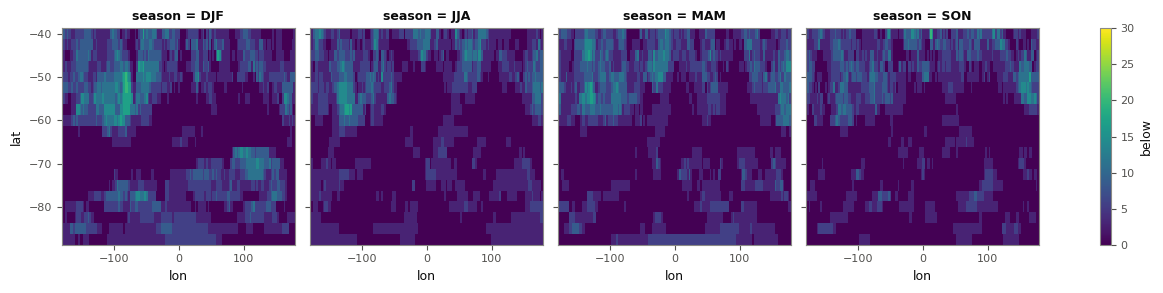

In [171]:
#(t): Quick look: the % of years ERA5 is below every member of EXAMPLE_MODEL, every season
spatial_table_ds['below'].sel(model=EXAMPLE_MODEL).plot(x='lon', y='lat', col='season', vmin=0, vmax=30);

## 9. Regional Evaluation

A regional mean averages away much of a grid point's noise, which is why the paper's verification is regional. Here the rank-histogram test of each region's mean, every model and experiment, anomalies and detrended: `regional_ranks`. ERA5's regional means are made as in notebook calc_03a, which saves them, with every member's and ERA5's regional trends.

In [172]:
#(t): The regions (observed_change.REGIONS), as in part 2 (notebook calc_03b)
oc.REGIONS

{'Antarctica (90–65°S)': {'lat': slice(-90, -65, None)},
 'Antarctic Peninsula': {'lat': slice(-75, -62.5, None),
  'lon': slice(-75, -55, None)},
 'Southern Ocean (65–50°S)': {'lat': slice(-65, -50, None)}}

In [173]:
#(t): ERA5's regional means, on (region, year, season)
era5_regional_da = oc.regional_means(era5_seasonal_da).rename(VARIABLE.name)
era5_regional_da

<xarray.DataArray 'tas' (region: 3, year: 45, season: 4)> Size: 4kB
-11.84 -30.17 -23.17 -22.84 -12.22 -26.79 ... 0.5159 3.797 -0.1756 2.763 0.5638
Coordinates:
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * year     (year) int64 360B 1979 1980 1981 1982 1983 ... 2020 2021 2022 2023
  * region   (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean (6...

In [175]:
%%time
#(t): Every member's regional means over the ERA5 years, every model and experiment
regional_obs_tree = oc.regional_means(lesfmip_obs_tree).compute()

CPU times: user 13 s, sys: 12.7 s, total: 25.6 s
Wall time: 9.08 s


**How `ev.rank_histogram_summary` puts every model's histogram on the same 10 bins** (`ev.regroup_ranks`), step by step on EXAMPLE_MODEL's histogram of anomalies at the point (*Every model*, above). Each model has its own number of members, so its own number of ranks; on 10 bins of scaled rank they can be drawn and compared together.

In [ ]:
#(t): EXAMPLE_MODEL's histogram: N ranks, rank r covering r / N to (r + 1) / N of the scaled rank
# Example: 3 ranks cover [0, 1/3), [1/3, 2/3) and [2/3, 1].
regroup_frequency_da = anomaly_ranks_ds['obs_frequency']
n_ranks = regroup_frequency_da.sizes['rank']
rank_edges_arr = np.linspace(0, 1, n_ranks + 1)

In [ ]:
#(t): The 10 new bins, each a tenth of the scaled rank
bin_edges_arr = np.linspace(0, 1, 10 + 1)

In [ ]:
#(t): How much of each rank falls in each bin: the length of their overlap, as a share of the rank's width
# Example: 3 ranks and 2 bins, [0, 0.5) and [0.5, 1]. Rank 1, [1/3, 2/3), overlaps bin 0 from 1/3 to 0.5 and bin 1 from
# 0.5 to 2/3. Each overlap is 1/6 long, half of the rank's width of 1/3, so rank 1 gives half of its frequency to each bin.
# Rank 0, [0, 1/3), lies inside bin 0, so it gives all of its frequency to bin 0.
# An overlap is the smaller of the two right edges minus the larger of the two left edges, and 0 if that is negative.
# rank_edges_arr[1:, None] puts the ranks' right edges down the rows and bin_edges_arr[None, 1:] the bins' across the
# columns, so every rank is compared with every bin at once. Dividing by the rank's width, 1 / N, is multiplying by N.
overlap_arr = np.clip(np.minimum(rank_edges_arr[1:, None], bin_edges_arr[None, 1:])
                      - np.maximum(rank_edges_arr[:-1, None], bin_edges_arr[None, :-1]), 0, None) * n_ranks

In [ ]:
#(t): Each bin's frequency: every rank's frequency times its share in the bin, added up over the ranks
# Example: 3 ranks with 30, 40 and 30 % of the samples. Bin 0 is given 30 + 0.5 * 40 = 50 %, and bin 1 0.5 * 40 + 30 = 50 %.
overlap_da = xr.DataArray(overlap_arr, dims=('rank', 'bin'))
regrouped_da = (regroup_frequency_da * overlap_da).sum('rank')

In [ ]:
#(t): Check: the steps against ev.regroup_ranks (largest difference: 0)
float(abs(regrouped_da.values - ev.regroup_ranks(regroup_frequency_da, 10).values).max())

In [ ]:
#(t): The regrouping step by step: a) EXAMPLE_MODEL's histogram, each of its N ranks a bar over its part of the scaled
#(t): rank; b) how much of each rank goes to each bin (overlap_arr); c) the 10 bins
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 9), layout='constrained')
ax1.bar(rank_edges_arr[:-1], regroup_frequency_da.values, width=1 / n_ranks, align='edge', color='0.6', edgecolor='white')
ax1.set(title=f'a) {n_ranks} ranks (flat: {100 / n_ranks:.1f}% each)', xlabel='scaled rank', ylabel='% of the samples',
        xlim=(0, 1))
overlap_image = ax2.imshow(overlap_arr, aspect='auto', cmap='Greys', vmin=0, vmax=1, interpolation='none',
                           extent=(0, 1, n_ranks, 0))
fig.colorbar(overlap_image, ax=ax2, location='bottom', shrink=0.5, label='share of the rank given to the bin')
ax2.set(title='b) How much of each rank goes to each bin (overlap_arr)', ylabel='rank')
ax3.bar(bin_edges_arr[:-1], regrouped_da.values, width=0.1, align='edge', color='0.6', edgecolor='white')
ax3.set(title='c) The 10 bins (flat: 10% each)', xlabel='scaled rank', ylabel='% of the samples', xlim=(0, 1));

In [177]:
%%time
#(t): Every model and experiment, regional means, anomalies: ev.rank_histogram_summary of each one's members against
#(t): ERA5's regional means over SATELLITE_YEAR_RANGE
regional_ranks_anomaly_tree = xr.DataTree.from_dict({
    node.path: ev.rank_histogram_summary(node['tas'], era5_regional_da.sel(year=SATELLITE_YEAR_RANGE), 'anomaly')
    for node in regional_obs_tree.leaves
})
regional_ranks_anomaly_ds = tree_to_dataset(regional_ranks_anomaly_tree, dims=['model', 'experiment'],
                                            coords='minimal', compat='override')

CPU times: user 3.84 s, sys: 29.4 ms, total: 3.87 s
Wall time: 3.93 s


In [178]:
%%time
#(t): ... and detrended anomalies
regional_ranks_detrended_tree = xr.DataTree.from_dict({
    node.path: ev.rank_histogram_summary(node['tas'], era5_regional_da.sel(year=SATELLITE_YEAR_RANGE), 'detrended')
    for node in regional_obs_tree.leaves
})
regional_ranks_detrended_ds = tree_to_dataset(regional_ranks_detrended_tree, dims=['model', 'experiment'],
                                              coords='minimal', compat='override')

CPU times: user 4.27 s, sys: 57.4 ms, total: 4.33 s
Wall time: 4.33 s


In [179]:
#(t): The two along a treatment dim
regional_ranks_ds = xr.concat([regional_ranks_anomaly_ds.drop_vars('treatment'),
                               regional_ranks_detrended_ds.drop_vars('treatment')],
                              dim=xr.Variable('treatment', ['anomaly', 'detrended']))
regional_ranks_ds

<xarray.Dataset> Size: 508kB
Dimensions:        (treatment: 2, statistic: 6, region: 3, season: 4, model: 6,
                    experiment: 5, rank: 10)
Coordinates:
  * model          (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment     (experiment) object 40B 'hist-GHG' ... 'historical'
  * season         (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * region         (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Oc...
  * statistic      (statistic) <U10 240B 'dispersion' 'outside' ... 'rank_trend'
    label          (statistic) <U17 408B 'Rank dispersion' ... 'Rank trend'
    units          (statistic) <U7 168B '' '%' '%' '%' '' '/decade'
  * rank           (rank) float64 80B 0.05 0.15 0.25 0.35 ... 0.75 0.85 0.95
  * treatment      (treatment) <U9 72B 'anomaly' 'detrended'
Data variables:
    era5           (treatment, statistic, region, season, model, experiment) float64 35kB ...
    lower          (treatment, statistic, region, season, model, experiment) float64 35kB ...
    median         (treatment, statistic, region, season, model, experiment) float64 35kB ...
    upper          (treatment, statistic, region, season, model, experiment) float64 35kB ...
    percentile     (treatment, statistic, region, season, model, experiment) float64 35kB ...
    pvalue         (treatment, statistic, region, season, model, experiment) float64 35kB ...
    verdict        (treatment, statistic, region, season, model, experiment) float64 35kB ...
    testable       (treatment, statistic, region, season, model, experiment) float64 35kB ...
    obs_frequency  (treatment, region, season, rank, model, experiment) float64 58kB ...
    pseudo_lower   (treatment, region, season, rank, model, experiment) float64 58kB ...
    pseudo_median  (treatment, region, season, rank, model, experiment) float64 58kB ...
    pseudo_upper   (treatment, region, season, rank, model, experiment) float64 58kB ...
Attributes: (4)

In [180]:
#(t): Saved for notebook plot_06
regional_ranks_path = RESULTS_DIR / 'regional_ranks.zarr'
regional_ranks_ds.to_zarr(regional_ranks_path, mode='w')
regional_ranks_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/regional_ranks.zarr')

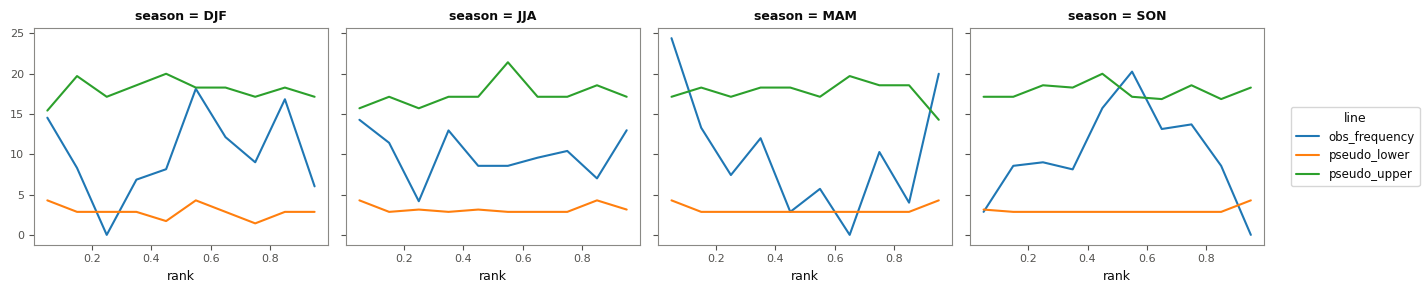

In [181]:
#(t): Quick look: EXAMPLE_MODEL's historical histograms (anomalies) in the first region, ERA5 against the perfect-model
#(t): range
regional_ranks_ds[['obs_frequency', 'pseudo_lower', 'pseudo_upper']].sel(
    model=EXAMPLE_MODEL, experiment='historical', treatment='anomaly').isel(region=0).to_dataarray('line').plot.line(
    x='rank', hue='line', col='season');